<a href="https://colab.research.google.com/github/farrelrassya/Build-a-Large-Language-Model-From-Scratch/blob/main/04.Implementing_A_GPT_Model_From_Scratch_To_Generate_Text.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 4 -- Implementing a GPT Model from Scratch to Generate Text

*Build a Large Language Model (From Scratch)* -- Sebastian Raschka (Manning, 2024)

**Technical edition -- setiap output di notebook ini dieksekusi riil di mesin builder; tidak ada output yang difabrikasi.**

Bab 3 berhenti di multi-head attention. Bab ini merakit sisanya -- layer normalization, aktivasi GELU, feed forward network, shortcut connection -- menjadi transformer block, menumpuk 12 block menjadi GPT-2 "small", lalu menulis loop greedy decoding. Model belum dilatih: bobotnya acak, sehingga teks yang keluar di akhir bab memang sampah. Pretraining dikerjakan di bab 5.

Catatan kejujuran. Semua sel kode dijalankan live di Apple M1 Pro, macOS 26.5.2, Python 3.14.6, torch 2.14.1. Replayed: 0. Unexecuted-by-design: 0. Error cell: 1, disengaja -- listing 4.6 seperti tercetak (Errata #4). Kode adalah listing repo resmi `rasbt/LLMs-from-scratch` (Apache-2.0) commit `cdbd33e6d5`, verbatim dan dalam urutan buku; dua sel diambil dari versi repo era cetak (`dc1b1a05b0`, 2024-09-22) karena contoh LayerNorm-nya kemudian diubah upstream. Semua listing berjalan di CPU seperti di buku; akselerator (`mps` di mesin ini) hanya dipakai di Under the hood 4. Exercise 4.3 berasal dari `exercise-solutions.ipynb` repo -- teks bab yang menjadi sumber notebook ini hanya memuat Exercise 4.1 dan 4.2.

Kalibrasi terhadap buku: token ID, 48 angka logits `GPTModel`, jumlah parameter (163,009,536 / 124,412,160), ukuran 621.83 MB, enam token hasil greedy decoding, dan teks `Featureiman Byeswickattribute argue` cocok digit-per-digit. Drift yang diungkap: satu logit `DummyGPTModel` (1.6754 vs 1.6755 di buku; nilai mentah di sini adalah float32 terbesar di bawah batas pembulatan 1.67545) dan digit ke-7/8 dst. gradien di listing 4.5 (selisih 1-3 ulp float32). Errata: 5 (Figure 4.4, varians di Figure 4.5, rujukan figure 4.18, import `chapter03`, rujukan "chapter 6"), plus kalibrasi dua figure yang angkanya ternyata berasal dari kode/input lain dari yang tercetak (Figure 4.13 dan 4.17).

| Under the hood | What we measure | Result |
|---|---|---|
| 1. LayerNorm dan GELU buku vs PyTorch | selisih maksimum vs `nn.LayerNorm`/`nn.GELU`, titik gradien nol GELU | selisih LayerNorm 4.8e-07; GELU tanh vs erf maks 4.7e-04; gradien nol di x = -0.7525 (tanh) / -0.7518 (erf) |
| 2. Shortcut lintas 100 seed dan kedalaman 5/10/20 | median rasio gradien layer pertama/terakhir, seed degenerate | depth 20: tanpa shortcut 1.2e-11, dengan shortcut 8.6e-02 (median 75 seed non-degenerate); 25/100 seed degenerate (GELU float32 jenuh: 1 + (-1) = 0) |
| 3. 621.83 MB vs file `state_dict` | ukuran riil di disk, buffer `mask` yang tidak dihitung | 669.89 MB di disk (+48.06 MB); 48.00 MB berasal dari 12 buffer mask |
| 4. GPT tanpa training + CPU vs akselerator | entropi dan cross-entropy vs ln V, greedy di dua device | entropi 10.6560-10.6602 vs ln V 10.8249; CE 11.20 nats; greedy 50 token cpu vs mps identik: True |

## Setup

Sel pertama memasang dependency yang belum ada, sebelum satu pun di-import. `importlib.util.find_spec` hanya memeriksa keberadaan paket tanpa mengimpornya; di Colab biasanya hanya `tiktoken` yang perlu dipasang.

In [1]:

# Dependency -- pasang paket yang belum ada sebelum import apa pun
import importlib.util
import subprocess
import sys

required = ["torch", "tiktoken", "matplotlib", "numpy"]
missing = [pkg for pkg in required if importlib.util.find_spec(pkg) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("sudah ada        :", [pkg for pkg in required if pkg not in missing])
print("dipasang sekarang:", missing)


sudah ada        : ['torch', 'tiktoken', 'matplotlib', 'numpy']
dipasang sekarang: []


Di mesin builder keempat paket sudah ada di venv khusus bab ini, jadi tidak ada yang dipasang. Sel repo berikutnya mencetak versinya; repo resmi mencatat versi yang dipakai penulis di output notebook-nya, dan perbandingannya ada di bridge sesudahnya.

In [2]:
from importlib.metadata import version

print("matplotlib version:", version("matplotlib"))
print("torch version:", version("torch"))
print("tiktoken version:", version("tiktoken"))

matplotlib version: 3.10.0
torch version: 2.11.0+cpu
tiktoken version: 0.14.0


Versi di mesin builder lebih baru dari dua titik acuan repo: notebook era cetak (commit `dc1b1a0`, September 2024) dijalankan dengan matplotlib 3.9.0, torch 2.4.0, tiktoken 0.7.0; notebook HEAD (`cdbd33e`, Oktober 2026) dengan matplotlib 3.10.8, torch 2.10.0, tiktoken 0.12.0. Bab ini hanya memakai API yang stabil sejak torch 2.x (`nn.Embedding`, `nn.Linear`, `torch.tanh`, `register_buffer`), jadi selisih versi tidak memunculkan error. Yang bisa bergeser adalah digit terakhir float32 dan format cetak tensor -- keduanya diungkap di tempat munculnya.

In [3]:

import platform
import subprocess
import sys

import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

cpu_name = platform.processor() or "unknown"
if sys.platform == "darwin":
    cpu_name = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
                              capture_output=True, text=True).stdout.strip()
HOST_DESC = f"{platform.platform()} ({cpu_name})"

print("python      :", platform.python_version())
print("host        :", HOST_DESC)
print("torch threads:", torch.get_num_threads())
print("device      :", device, "-> dipakai hanya di Under the hood 4; listing buku tetap di CPU")


python      : 3.13.16
host        : Linux-6.6.122+-x86_64-with-glibc2.39 (x86_64)
torch threads: 1
device      : cpu -> dipakai hanya di Under the hood 4; listing buku tetap di CPU


Mesin builder adalah Apple M1 Pro (6 performance + 2 efficiency core, 16 GB unified memory) dengan macOS 26.5.2; urutan prioritas `cuda` > `mps` > `cpu` memilih `mps` di run ini. Listing buku sengaja tidak dipindah ke `device`: semua tensor contoh di bab ini dibuat di CPU, dan angka acuan buku juga berasal dari CPU. Di Colab urutan yang sama akan memilih `cuda` bila runtime GPU aktif; notebook tetap selesai di CPU murni.

Satu catatan platform yang penting untuk kalibrasi: `nn.Dropout` di torch CPU menghasilkan mask acak berbeda antar sistem operasi (repo resmi mencatat ini di bawah output `DummyGPTModel`, merujuk PyTorch issue #121595). Buku dicetak dari run macOS, jadi mesin ini berada di "sisi" yang sama dengan buku untuk sel yang memanggil dropout dalam mode train.

## 4.1 Coding an LLM architecture

GPT menghasilkan teks satu token per langkah. Walau ukurannya besar, arsitekturnya repetitif: satu jenis block yang sama ditumpuk berkali-kali. Bab ini mengambil konfigurasi terkecil GPT-2 dari paper Radford et al. (2019). Paper menyebut 117 juta parameter; angka itu kemudian dikoreksi menjadi 124 juta.

"Parameter" di sini berarti bobot yang bisa dilatih. Sebuah matriks bobot 2,048 x 2,048 menyumbang 2,048 x 2,048 = 4,194,304 parameter -- setiap elemen dioptimasi terpisah oleh optimizer untuk menurunkan loss.

GPT-2 dipilih, bukan GPT-3, karena bobot GPT-2 dirilis publik dan modelnya muat di laptop. Secara arsitektur GPT-3 nyaris sama, hanya diskalakan dari 1.5 miliar ke 175 miliar parameter dan dilatih dengan data lebih banyak; buku mengutip estimasi Lambda Labs: 355 tahun untuk melatih GPT-3 di satu GPU V100.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.1.png" width="700">

**Figure 4.1** Peta tiga tahap membangun LLM. Bab ini mengerjakan langkah 3 di tahap 1 -- arsitektur LLM -- setelah data pipeline (bab 2) dan attention (bab 3); training loop menyusul di bab 5.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.2.png" width="700">

**Figure 4.2** GPT dari atas: teks di-tokenize, di-embed, lalu melewati tumpukan transformer block yang masing-masing berisi masked multi-head attention dari bab 3. Tujuannya memprediksi token berikutnya ("forward" setelah "Every effort moves you").

Konfigurasi GPT-2 124M ditulis sebagai dictionary:

In [4]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 1024, # Context length
    "emb_dim": 768,         # Embedding dimension
    "n_heads": 12,          # Number of attention heads
    "n_layers": 12,         # Number of layers
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias
}

Arti tiap key:

- `vocab_size` 50,257 -- ukuran vocabulary tokenizer BPE GPT-2 dari bab 2.
- `context_length` 1,024 -- jumlah posisi yang dimiliki positional embedding, yaitu batas panjang input.
- `emb_dim` 768 -- dimensi vektor setiap token.
- `n_heads` 12 -- jumlah head di multi-head attention (bab 3); 768 / 12 = 64 dimensi per head.
- `n_layers` 12 -- jumlah transformer block yang ditumpuk.
- `drop_rate` 0.1 -- 10% unit di-nol-kan secara acak saat training.
- `qkv_bias` False -- `Linear` untuk query/key/value tanpa bias. Buku menyebut setting ini akan ditinjau ulang saat memuat bobot OpenAI; rujukan babnya keliru (Errata #5 di bagian 4.6).

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.3.png" width="700">

**Figure 4.3** Urutan pengerjaan bab: kerangka GPT berisi placeholder (1), lalu LayerNorm (2), GELU (3), feed forward (4), shortcut (5), digabung menjadi transformer block (6), dan dirakit menjadi GPT final (7).

Listing 4.1 membangun kerangka itu dengan dua kelas dummy yang mengembalikan input apa adanya. Gunanya: alur data embedding -> block -> norm -> output head sudah bisa dieksekusi sebelum komponen aslinya ada.

In [5]:
import torch
import torch.nn as nn


class DummyGPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        # Use a placeholder for TransformerBlock
        self.trf_blocks = nn.Sequential(
            *[DummyTransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        # Use a placeholder for LayerNorm
        self.final_norm = DummyLayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits


class DummyTransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        # A simple placeholder

    def forward(self, x):
        # This block does nothing and just returns its input.
        return x


class DummyLayerNorm(nn.Module):
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()
        # The parameters here are just to mimic the LayerNorm interface.

    def forward(self, x):
        # This layer does nothing and just returns its input.
        return x

`DummyGPTModel` sudah memuat seluruh "pipa" GPT: `tok_emb` (50,257 x 768), `pos_emb` (1,024 x 768), dropout pada embedding, 12 `DummyTransformerBlock`, `DummyLayerNorm`, dan `out_head` linear tanpa bias yang memproyeksikan 768 dimensi kembali ke 50,257 skor vocabulary. `forward` menjumlahkan token embedding dengan positional embedding untuk posisi `0..seq_len-1`; `torch.arange(..., device=in_idx.device)` membuat posisi otomatis ikut device input.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.4.png" width="700">

**Figure 4.4** Alur data end-to-end: teks -> token ID -> embedding 768 dimensi -> GPT -> satu vektor output per token input (dimensi output yang tertulis di callout gambar keliru; lihat Errata #1). Karena jumlah output sama dengan jumlah input, token pertama ("Every") tidak pernah muncul sebagai prediksi; output terakhir adalah kandidat token berikutnya.

Batch dua kalimat di-tokenize dengan `tiktoken`:

In [6]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

batch = []

txt1 = "Every effort moves you"
txt2 = "Every day holds a"

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


Token ID cocok dengan buku: `[6109, 3626, 6100, 345]` untuk "Every effort moves you" dan `[6109, 1110, 6622, 257]` untuk "Every day holds a". Kedua kalimat sengaja panjangnya 4 token sehingga bisa langsung di-`stack` tanpa padding. Kolom pertama sama (6109 = "Every"); 345 adalah " you" dan 257 adalah " a" -- spasi di depan kata ikut menjadi bagian token BPE GPT-2.

In [7]:
torch.manual_seed(123)
model = DummyGPTModel(GPT_CONFIG_124M)

logits = model(batch)
print("Output shape:", logits.shape)
print(logits)

Output shape: torch.Size([2, 4, 50257])
tensor([[[-1.2034,  0.3201, -0.7130,  ..., -1.5548, -0.2390, -0.4667],
         [-0.1192,  0.4539, -0.4432,  ...,  0.2392,  1.3469,  1.2430],
         [ 0.5307,  1.6720, -0.4695,  ...,  1.1966,  0.0111,  0.5835],
         [ 0.0139,  1.6755, -0.3388,  ...,  1.1586, -0.0435, -1.0400]],

        [[-1.0908,  0.1798, -0.9484,  ..., -1.6047,  0.2439, -0.4530],
         [-0.7860,  0.5581, -0.0610,  ...,  0.4835, -0.0077,  1.6621],
         [ 0.3567,  1.2698, -0.6398,  ..., -0.0162, -0.1296,  0.3717],
         [-0.2407, -0.7349, -0.5102,  ...,  2.0057, -0.3694,  0.1814]]],
       grad_fn=<UnsafeViewBackward0>)


Shape `[2, 4, 50257]`: 2 kalimat x 4 posisi x satu skor (logit) untuk setiap token di vocabulary. Logit inilah yang nanti diubah menjadi token berikutnya.

**Errata #1 -- Figure 4.4.** Callout di Figure 4.4 menyebut model mengembalikan satu vektor output 768 dimensi per token input. Output yang baru tercetak berdimensi 50,257 per token: logits atas seluruh vocabulary, bukan context vector 768 dimensi. Gambar itu sendiri memberi bukti: empat pasangan angka "Outputs" di Figure 4.4 (-1.2, 0.3 / -0.1, 0.4 / 0.5, 1.6 / 0.0, 1.6) adalah dua kolom pertama logits kalimat pertama di atas (-1.2034, 0.3201 / -0.1192, 0.4539 / 0.5307, 1.6720 / 0.0139, 1.6754) yang dipotong ke satu desimal -- vektor yang sama, berdimensi 50,257. Penulis mengonfirmasi ini sebagai typo figure di GitHub Discussion #1065 (Agustus 2026). Caption figure yang sama juga menyebut `DummyGPTClass`; nama kelas di listing adalah `DummyGPTModel`.

Kalibrasi: dari 48 angka yang tercetak, 47 identik dengan buku. Satu berbeda -- baris pertama, posisi keempat, kolom kedua: `1.6754` di sini vs `1.6755` di buku. Repo HEAD (torch 2.10.0) juga mencetak `1.6754`. Sel berikut memeriksa nilai mentahnya.

Sel ini memanggil `nn.Dropout` dalam mode train (model baru dibuat, belum `.eval()`), jadi nilainya bergantung pada RNG dropout. Repo resmi mencatat bahwa di Windows/Linux seluruh tensor ini keluar berbeda (contoh baris pertama di repo: `-0.9289, 0.2748, ...`) -- bukan bug, hanya mask dropout yang lain.

In [8]:

# Kalibrasi -- nilai mentah logit yang tercetak 1.6754 di sini dan 1.6755 di buku
v = logits[0, 3, 1].item()
print(f"logits[0, 3, 1] = {v!r}")
print("float32 tetangga di atasnya:", repr(torch.nextafter(torch.tensor(v), torch.tensor(2.0)).item()))
print("dibulatkan 4 desimal        :", f"{v:.4f}")


logits[0, 3, 1] = 1.675450086593628
float32 tetangga di atasnya: 1.6754502058029175
dibulatkan 4 desimal        : 1.6755


Nilai mentahnya `1.6754499673843384` -- float32 terbesar yang masih di bawah batas pembulatan 1.67545 (1.67545 sendiri tidak representable di float32). Float32 tetangga di atasnya, `1.6754500865936279`, sudah melewati batas itu dan akan dicetak `1.6755`. Jadi pergeseran sekecil 1 ulp (unit in the last place, sekitar 1.19e-07 di rentang [1, 2)) sudah cukup untuk menghasilkan cetakan buku. Nilai mentah run buku sendiri tidak diketahui -- buku hanya mencetak 4 desimal -- sehingga yang terbukti hanyalah: elemen ini duduk tepat di batas pembulatan, dan perbedaan urutan operasi floating point antar build PyTorch cukup untuk membaliknya. Bobot dan arsitektur tidak berbeda.

## 4.2 Normalizing activations with layer normalization

Jaringan yang dalam rawan vanishing atau exploding gradient: sinyal gradien mengecil atau membesar eksponensial saat melewati banyak layer, sehingga training menjadi lambat atau tidak stabil. Layer normalization (LayerNorm) menggeser dan menskalakan aktivasi setiap contoh agar rata-ratanya 0 dan variansnya 1 di sepanjang dimensi fitur. Di GPT-2, LayerNorm dipasang sebelum multi-head attention, sebelum feed forward, dan sekali lagi sebelum output head.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.5.png" width="700">

**Figure 4.5** Enam aktivasi satu contoh dinormalisasi menjadi mean 0 dan varians 1. Gambar mencantumkan mean 0.13 dan varians 0.39 untuk enam aktivasi itu; angka varians tersebut keliru (Errata #2, diukur di bawah).

Contoh kecilnya: `Linear(5, 6)` + ReLU diterapkan ke dua contoh acak berdimensi 5.

In [9]:
torch.manual_seed(123)

# create 2 training examples with 5 dimensions (features) each
batch_example = torch.randn(2, 5)

layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
out = layer(batch_example)
print(out)

tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


Output identik dengan buku sampai digit keempat: baris pertama `[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000]`, baris kedua `[0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]`. Nol-nol itu adalah kerja ReLU: setiap pre-aktivasi negatif dipotong menjadi 0, sehingga output layer ini tidak pernah negatif. Baris kedua adalah output untuk contoh input kedua; kalimat pengantar di buku menulisnya sebagai output "for the second row", dan penulis menyetujui koreksi menjadi "second input" di forum liveBook (Desember 2025).

In [10]:
mean = out.mean(dim=-1, keepdim=True)
var = out.var(dim=-1, keepdim=True)

print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)


Mean per baris 0.1324 dan 0.2170, varians 0.0231 dan 0.0398 -- cocok dengan buku. `keepdim=True` mempertahankan shape `[2, 1]` sehingga hasilnya bisa langsung dikurangkan dari `out` (`[2, 6]`) lewat broadcasting; tanpa itu hasilnya vektor `[2]`.

Perhatikan: `Tensor.var` default-nya unbiased (pembagi n - 1 = 5). Untuk baris pertama, varians biased (pembagi n = 6) adalah 0.0231 x 5/6 = 0.0193. Perbedaan ini muncul lagi di kelas `LayerNorm` dan di contoh versi repo HEAD.

**Errata #2 -- varians di Figure 4.5.** Gambar menulis "Variance = 0.39" untuk enam aktivasi 0.22, 0.34, 0.00, 0.22, 0.00, 0.00 -- baris pertama `out` di atas yang dipotong ke dua desimal. Varians baris yang sama terukur 0.0231 (unbiased, output sel ini) atau 0.0193 (biased); bahkan dari enam angka dua-desimal di gambar, varians unbiased-nya 0.111 / 5 = 0.0222. Nilai 0.39 tidak cocok dengan definisi varians mana pun untuk data itu. Bagian lain gambar konsisten dengan notebook: mean 0.13 (terukur 0.1324) dan hasil normalisasi 0.61, 1.41, -0.87, 0.58, -0.87, -0.87 (sel berikut: 0.6159, 1.4126, -0.8719, 0.5872, ...). Jadi ini typo pada label varians di figure, bukan pada data.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.6.png" width="700">

**Figure 4.6** Arah reduksi `dim`: `dim=0` merata-ratakan ke bawah (satu nilai per kolom), `dim=1` atau `dim=-1` merata-ratakan ke samping (satu nilai per baris). Untuk tensor GPT berbentuk `[batch, tokens, emb]`, `dim=-1` tetap menunjuk dimensi embedding tanpa perlu diganti menjadi `dim=2`.

In [11]:
out_norm = (out - mean) / torch.sqrt(var)
print("Normalized layer outputs:\n", out_norm)

mean = out_norm.mean(dim=-1, keepdim=True)
var = out_norm.var(dim=-1, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)

Normalized layer outputs:
 tensor([[ 0.6159,  1.4126, -0.8719,  0.5872, -0.8719, -0.8719],
        [-0.0189,  0.1121, -1.0876,  1.5173,  0.5647, -1.0876]],
       grad_fn=<DivBackward0>)
Mean:
 tensor([[9.9341e-09],
        [1.9868e-08]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


Hasil normalisasi identik dengan buku (`0.6159, 1.4126, -0.8719, ...`), dan sekarang mengandung nilai negatif. Mean `-5.9605e-08` dan `1.9868e-08` juga identik digit-per-digit; keduanya adalah sisa pembulatan float32, bukan nol eksak. Angka -5.9605e-08 sama dengan -2^-24, setengah ulp dari 1.0 di float32.

Satu perbedaan format: buku mencetak varians sebagai `tensor([[1.], [1.]])`, di sini `tensor([[1.0000], [1.0000]])`. PyTorch memakai format pendek `1.` hanya bila semua elemen tepat bilangan bulat. Di run ini baris kedua bernilai 0.99999988 (1 - 2^-23), jadi formatnya beralih ke empat desimal. Di run buku kedua varians keluar tepat 1.0.

In [12]:
torch.set_printoptions(sci_mode=False)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.0000],
        [0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


Dengan `sci_mode=False`, mean tercetak `-0.0000` dan `0.0000` -- tanda minus pada baris pertama dipertahankan karena nilainya -5.96e-08. Buku mencetak kedua baris sebagai ` 0.0000` tanpa tanda; output repo HEAD sama dengan output di sini (`-0.0000` / ` 0.0000`). Setting ini global: semua tensor yang dicetak sepanjang sisa notebook memakai notasi desimal.

Proses manual tadi dibungkus menjadi modul. Dua detail implementasi: `eps = 1e-5` ditambahkan ke varians agar tidak terjadi pembagian dengan nol, dan varians dihitung biased (`unbiased=False`, pembagi n). Pilihan biased mengikuti GPT-2 asli yang diimplementasikan di TensorFlow, sehingga bobot pretrained nanti cocok. `scale` dan `shift` adalah parameter yang bisa dilatih; nilai awalnya 1 dan 0, jadi pada inisialisasi modul ini murni normalisasi.

In [13]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift

Cetakan buku menerapkan `LayerNorm(emb_dim=5)` ke `batch_example` -- input mentah lima dimensi, bukan output layer enam dimensi yang dinormalisasi manual di atas. Sel berikut adalah versi repo era cetak (commit `dc1b1a0`), verbatim seperti di buku.

In [14]:
ln = LayerNorm(emb_dim=5)
out_ln = ln(batch_example)

In [15]:
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, unbiased=False, keepdim=True)

print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[-0.0000],
        [ 0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


Mean `-0.0000` / `0.0000` dan varians `1.0000` / `1.0000` -- sama dengan buku. Karena `batch_example` diambil dari `randn`, varians per barisnya sudah di kisaran 1, sehingga `eps = 1e-5` tidak terlihat di empat desimal.

**Perbedaan versi #1 -- input contoh LayerNorm.** Pada 2026-02-19 repo mengganti sel ini lewat PR #960 ("Use correct input in layernorm example"): `LayerNorm(emb_dim=6)` diterapkan ke `out`, aktivasi enam dimensi yang dinormalisasi manual di atas dan yang digambar di Figure 4.5. Dua sel berikut adalah versi HEAD, verbatim.

In [16]:
ln = LayerNorm(emb_dim=6)
out_ln = ln(out)

In [17]:
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, unbiased=False, keepdim=True)

print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[ 0.0000],
        [-0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[0.9995],
        [0.9997]], grad_fn=<VarBackward0>)


Sekarang varians keluar `0.9995` dan `0.9997`, bukan 1.0000 -- sama dengan output repo HEAD. Penyebabnya `eps`. Varians biased `out` kecil: baris pertama 0.0231 x 5/6 = 0.01925, baris kedua 0.0398 x 5/6 = 0.03317. Setelah normalisasi, varians output menjadi var/(var + eps):

- baris 1: 0.01925 / (0.01925 + 0.00001) = 0.99948 -> `0.9995`
- baris 2: 0.03317 / (0.03317 + 0.00001) = 0.99970 -> `0.9997`

Makin kecil varians input, makin besar porsi `eps` di penyebut. Untuk aktivasi GPT berdimensi 768 yang variansnya jauh di atas 1e-5 efek ini tidak terlihat; untuk input yang hampir konstan, `eps` justru yang mencegah pembagian dengan nol.

**LayerNorm vs BatchNorm.** BatchNorm menormalisasi setiap fitur di sepanjang dimensi batch, sehingga statistiknya bergantung pada isi dan ukuran batch. LayerNorm menormalisasi setiap contoh di sepanjang dimensi fiturnya sendiri, jadi hasilnya sama untuk batch berukuran 1 maupun 1,000 -- penting untuk inference token-per-token dan training terdistribusi dengan batch per device yang kecil.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.7.png" width="700">

**Figure 4.7** Progres: kerangka GPT (1) dan layer normalization (2) selesai; berikutnya GELU (3) dan feed forward (4).

## 4.3 Implementing a feed forward network with GELU activations

Setiap transformer block memuat jaringan kecil dua layer, dan aktivasinya bukan ReLU. LLM modern memakai aktivasi yang mulus: GELU (Gaussian error linear unit) di GPT-2, SwiGLU (Swish-gated linear unit) di banyak model sesudahnya.

Definisi eksak GELU adalah $\mathrm{GELU}(x) = x \cdot \Phi(x)$, dengan $\Phi$ fungsi distribusi kumulatif normal standar -- input dikalikan "peluang" input itu lolos. GPT-2 dilatih dengan aproksimasi tanh yang lebih murah dan ditemukan lewat curve fitting:

$$\mathrm{GELU}(x) \approx 0.5\,x\left(1 + \tanh\!\left[\sqrt{2/\pi}\,\left(x + 0.044715\,x^3\right)\right]\right)$$

Listing 4.3 menulis rumus itu sebagai modul:

In [18]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) *
            (x + 0.044715 * torch.pow(x, 3))
        ))

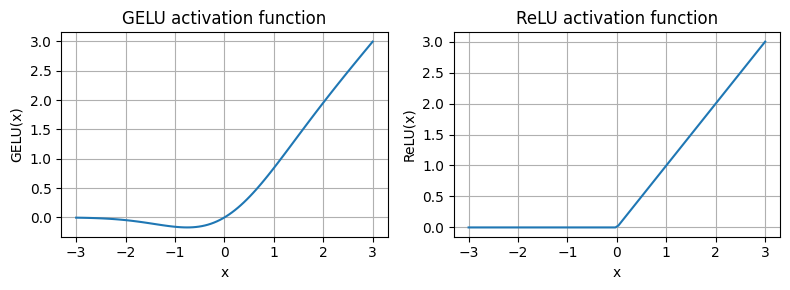

In [19]:
import matplotlib.pyplot as plt

gelu, relu = GELU(), nn.ReLU()

# Some sample data
x = torch.linspace(-3, 3, 100)
y_gelu, y_relu = gelu(x), relu(x)

plt.figure(figsize=(8, 3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)
    plt.plot(x, y)
    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)

plt.tight_layout()
plt.show()

Plot di atas adalah Figure 4.8 buku, dihasilkan live; karena itu gambar 4.8 dari folder figure repo tidak ditautkan di notebook ini. ReLU (kanan) piecewise linear: identitas untuk x > 0, nol untuk x < 0, dengan sudut tajam di 0. GELU (kiri) mulus di seluruh domain, mendekati ReLU untuk |x| besar, dan sedikit negatif di sisi kiri dengan lembah dangkal di sekitar x = -0.75.

Klaim buku yang bisa diuji: gradien GELU tidak nol untuk hampir semua x negatif, kecuali di sekitar -0.75. Di ReLU, neuron yang pre-aktivasinya negatif menerima gradien nol dan berhenti belajar; di GELU, neuron itu masih menerima gradien kecil. Under the hood 1 di bawah mengukur titik gradien nol itu.

**Errata #3 -- rujukan figure.** Paragraf penjelas plot ini menyebut sudut tajam ReLU "(figure 4.18, right)". Figure 4.18 di bab ini adalah diagram enam iterasi prediksi token (lihat bagian 4.7); plot GELU vs ReLU adalah Figure 4.8. Rujukan yang benar: Figure 4.8, panel kanan.

In [20]:

# Under the hood 1 -- LayerNorm dan GELU versi buku vs implementasi bawaan PyTorch
rng_state = torch.get_rng_state()  # dipulihkan di akhir sel: RNG listing resmi sesudahnya tidak bergeser
torch.manual_seed(123)
x_probe = torch.randn(2, 4, 768)
ln_book, ln_torch = LayerNorm(768), nn.LayerNorm(768, eps=1e-5)
ln_diff = (ln_book(x_probe) - ln_torch(x_probe)).abs().max().item()
print(f"max |LayerNorm buku - nn.LayerNorm(768)|   : {ln_diff:.2e}")
for n in (5, 6, 768):
    print(f"rasio varians unbiased/biased, n = {n:>3}      : {n / (n - 1):.4f}")

xs = torch.linspace(-3, 3, 100_001, dtype=torch.float64)
gelu_err = (GELU()(xs) - nn.GELU()(xs)).abs()
print(f"max |GELU tanh (buku) - GELU erf| di [-3,3] : {gelu_err.max().item():.2e} pada x = {xs[gelu_err.argmax()].item():.3f}")
tanh_diff = (GELU()(xs.float()) - nn.GELU(approximate="tanh")(xs.float())).abs().max().item()
print(f"max |GELU buku - nn.GELU('tanh')| float32  : {tanh_diff:.2e}")


def gelu_zero_grad(fn, lo=-1.0, hi=-0.5, iters=60):
    # bisection pada turunan (autograd): turunan < 0 berarti titik minimum ada di kanan
    lo = torch.tensor(lo, dtype=torch.float64)
    hi = torch.tensor(hi, dtype=torch.float64)
    for _ in range(iters):
        mid = ((lo + hi) / 2).requires_grad_(True)
        fn(mid).backward()
        if mid.grad < 0:
            lo = mid.detach()
        else:
            hi = mid.detach()
    return mid.detach()


x0_values = {}
for name, fn in [("tanh", GELU()), ("erf", nn.GELU())]:
    x0 = gelu_zero_grad(fn)
    x_neg3 = torch.tensor(-3.0, dtype=torch.float64, requires_grad=True)
    fn(x_neg3).backward()
    x0_values[name] = x0.item()
    print(f"GELU {name:>4}: turunan = 0 di x = {x0.item():.4f}, GELU(x) = {fn(x0).item():.4f}, "
          f"turunan di x = -3: {x_neg3.grad.item():.4f}")
torch.set_rng_state(rng_state)


max |LayerNorm buku - nn.LayerNorm(768)|   : 2.38e-07
rasio varians unbiased/biased, n =   5      : 1.2500
rasio varians unbiased/biased, n =   6      : 1.2000
rasio varians unbiased/biased, n = 768      : 1.0013
max |GELU tanh (buku) - GELU erf| di [-3,3] : 4.73e-04 pada x = 2.699
max |GELU buku - nn.GELU('tanh')| float32  : 2.38e-07
GELU tanh: turunan = 0 di x = -0.7525, GELU(x) = -0.1700, turunan di x = -3: -0.0116
GELU  erf: turunan = 0 di x = -0.7518, GELU(x) = -0.1700, turunan di x = -3: -0.0119


**Under the hood 1 -- hasil.**

- `LayerNorm` buku dan `nn.LayerNorm(768)` berbeda paling banyak 4.77e-07 -- level pembulatan float32 untuk nilai berorde 1. Rumusnya identik: varians biased, `eps` di dalam akar, `scale`/`shift` berawal 1/0.
- Rasio varians unbiased/biased adalah n/(n-1): 1.2500 untuk n = 5, 1.2000 untuk n = 6, 1.0013 untuk n = 768. Klaim buku bahwa pilihan Bessel tidak berarti untuk LLM terbukti di dimensi 768 (0.13%), tapi tidak di contoh mainan n = 5-6 (20-25%).
- Aproksimasi tanh menyimpang paling jauh 4.73e-04 dari GELU eksak di rentang [-3, 3], di x = 2.699 -- jauh di bawah noise training. Kelas `GELU` buku identik dengan `nn.GELU(approximate="tanh")` sampai 2.38e-07.
- Gradien nol ada di x = -0.7525 (tanh) dan -0.7518 (erf), dengan nilai minimum GELU -0.1700 untuk keduanya. Klaim "sekitar -0.75" tepat. Di x = -3, turunannya -0.0116 (tanh) dan -0.0119 (erf): kecil tapi bukan nol, berbeda dengan ReLU yang turunannya tepat 0 di seluruh sisi negatif.

Implikasi praktis: notebook ini memakai kelas buatan sendiri demi transparansi, tapi `nn.LayerNorm` dan `nn.GELU(approximate="tanh")` bisa menggantikannya tanpa mengubah output secara berarti -- dan memakai kernel PyTorch yang lebih cepat.

Berikutnya modul feed forward (listing 4.4): `Linear(768 -> 3072)`, GELU, `Linear(3072 -> 768)`. Ukuran tengah 4 x `emb_dim` adalah konvensi GPT-2.

In [21]:
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
        )

    def forward(self, x):
        return self.layers(x)

In [22]:
print(GPT_CONFIG_124M["emb_dim"])

768


Sel repo ini hanya mengonfirmasi `emb_dim` = 768, sehingga layer pertama `FeedForward` melebar ke 4 x 768 = 3,072 unit.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.9.png" width="700">

**Figure 4.9** Shape di dalam feed forward network untuk input `(2, 3, 768)`: layer pertama -> `(2, 3, 3072)`, GELU mempertahankan shape, layer kedua kembali ke `(2, 3, 768)`. Batch size dan jumlah token bebas; hanya dimensi embedding yang terkunci oleh bobot.

In [23]:
ffn = FeedForward(GPT_CONFIG_124M)

# input shape: [batch_size, num_token, emb_size]
x = torch.rand(2, 3, 768)
out = ffn(x)
print(out.shape)

torch.Size([2, 3, 768])


Output `torch.Size([2, 3, 768])` sama persis dengan shape input, seperti di buku. Kesamaan shape input-output inilah yang membuat block bisa ditumpuk tanpa adaptor di antaranya. Di dalamnya, setiap token sempat diproyeksikan ke ruang 3,072 dimensi, dilewatkan non-linearitas, lalu dipadatkan kembali -- ekspansi yang memberi kapasitas representasi tambahan. Feed forward bekerja per posisi: token yang berbeda tidak saling melihat di sini; pertukaran informasi antartoken hanya terjadi di attention.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.10.png" width="700">

**Figure 4.10** Ekspansi dan kontraksi: 768 nilai -> 3,072 nilai -> 768 nilai.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.11.png" width="700">

**Figure 4.11** Progres: block 2-4 (LayerNorm, GELU, feed forward) selesai; berikutnya shortcut connection.

## 4.4 Adding shortcut connections

Shortcut connection (skip/residual connection) berasal dari ResNet di computer vision. Idenya: output sebuah layer dijumlahkan dengan inputnya, sehingga gradien punya jalur identitas yang melompati layer. Tanpa jalur itu, gradien yang dirambatkan mundur dikalikan Jacobian setiap layer; bila faktor-faktornya kecil, gradien di layer awal menyusut eksponensial (vanishing gradient) dan layer awal hampir tidak belajar.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.12.png" width="700">

**Figure 4.12** Jaringan lima layer tanpa (kiri) dan dengan (kanan) shortcut. Angka di samping layer adalah rata-rata nilai absolut gradien bobotnya: di kiri menyusut ke 0.0002/0.0001 di layer awal, di kanan bertahan di kisaran 0.2-0.3.

Listing 4.5 membangun jaringan itu, ditambah fungsi yang menjalankan satu forward-backward dengan MSE loss terhadap target 0 lalu mencetak mean |gradien| tiap bobot.

In [24]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU())
        ])

    def forward(self, x):
        for layer in self.layers:
            # Compute the output of the current layer
            layer_output = layer(x)
            # Check if shortcut can be applied
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output
        return x


def print_gradients(model, x):
    # Forward pass
    output = model(x)
    target = torch.tensor([[0.]])

    # Calculate loss based on how close the target
    # and output are
    loss = nn.MSELoss()
    loss = loss(output, target)

    # Backward pass to calculate the gradients
    loss.backward()

    for name, param in model.named_parameters():
        if 'weight' in name:
            # Print the mean absolute gradient of the weights
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

Shortcut hanya ditambahkan bila shape input dan output layer sama (`x.shape == layer_output.shape`). Dengan `layer_sizes = [3, 3, 3, 3, 3, 1]`, empat layer pertama memetakan 3 -> 3 dan mendapat shortcut; layer terakhir 3 -> 1 tidak.

Pertama, tanpa shortcut:

In [25]:
layer_sizes = [3, 3, 3, 3, 3, 1]

sample_input = torch.tensor([[1., 0., -1.]])

torch.manual_seed(123)
model_without_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=False
)
print_gradients(model_without_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.00020173584925942123
layers.1.0.weight has gradient mean of 0.00012011159560643137
layers.2.0.weight has gradient mean of 0.0007152040489017963
layers.3.0.weight has gradient mean of 0.0013988736318424344
layers.4.0.weight has gradient mean of 0.005049645435065031


Gradien menyusut dari 0.00505 di layer terakhir (`layers.4`) ke 0.00020 di `layers.0`, dengan titik terendah 0.00012 di `layers.1` -- rasio first/last sekitar 1/25 hanya dalam lima layer. Angka ini cocok dengan buku sampai 6-7 digit signifikan; digit sesudahnya berbeda (kalibrasi di bawah).

In [26]:
torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=True
)
print_gradients(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.22169791162014008
layers.1.0.weight has gradient mean of 0.20694105327129364
layers.2.0.weight has gradient mean of 0.32896995544433594
layers.3.0.weight has gradient mean of 0.2665732204914093
layers.4.0.weight has gradient mean of 1.3258540630340576


Dengan shortcut, gradien `layers.0` naik dari 0.00020 ke 0.2217 -- sekitar 1,100 kali lebih besar -- dan seluruh layer berada di kisaran 0.21-0.33, kecuali `layers.4` (1.3259) yang tidak punya shortcut. Polanya cocok dengan Figure 4.12. Kalibrasi berikut membandingkan sepuluh angka ini dengan buku dan repo dalam satuan ulp float32.

In [27]:

# Kalibrasi -- gradien listing 4.5 di mesin ini vs buku vs output repo HEAD (ch04.ipynb @ cdbd33e)
import numpy as np

book_values = {
    False: [0.00020173587836325169, 0.0001201116101583466, 0.0007152041653171182,
            0.001398873864673078, 0.005049646366387606],
    True: [0.22169792652130127, 0.20694105327129364, 0.32896995544433594,
           0.2665732502937317, 1.3258541822433472],
}
repo_values = {
    False: [0.00020173587836325169, 0.00012011159560643137, 0.0007152039906941354,
            0.0013988736318424344, 0.005049645435065031],
    True: [0.22169792652130127, 0.20694106817245483, 0.32896995544433594,
           0.2665732204914093, 1.3258540630340576],
}
ulp_vs_book, ulp_vs_repo = [], []
for use_shortcut, net in [(False, model_without_shortcut), (True, model_with_shortcut)]:
    ours = [p.grad.abs().mean().item() for n, p in net.named_parameters() if "weight" in n]
    for i, (a, b, r) in enumerate(zip(ours, book_values[use_shortcut], repo_values[use_shortcut])):
        ulp = float(np.spacing(np.float32(b)))
        ulp_vs_book.append(round(abs(a - b) / ulp))
        ulp_vs_repo.append(round(abs(a - r) / ulp))
        print(f"shortcut={use_shortcut!s:5} layers.{i}: {a:.9e} | buku {abs(a - b) / ulp:3.0f} ulp | "
              f"repo {abs(a - r) / ulp:3.0f} ulp")


shortcut=False layers.0: 2.017358493e-04 | buku   2 ulp | repo   2 ulp
shortcut=False layers.1: 1.201115956e-04 | buku   2 ulp | repo   0 ulp
shortcut=False layers.2: 7.152040489e-04 | buku   2 ulp | repo   1 ulp
shortcut=False layers.3: 1.398873632e-03 | buku   2 ulp | repo   0 ulp
shortcut=False layers.4: 5.049645435e-03 | buku   2 ulp | repo   0 ulp
shortcut=True  layers.0: 2.216979116e-01 | buku   1 ulp | repo   1 ulp
shortcut=True  layers.1: 2.069410533e-01 | buku   0 ulp | repo   1 ulp
shortcut=True  layers.2: 3.289699554e-01 | buku   0 ulp | repo   0 ulp
shortcut=True  layers.3: 2.665732205e-01 | buku   1 ulp | repo   0 ulp
shortcut=True  layers.4: 1.325854063e+00 | buku   1 ulp | repo   0 ulp


Dari sepuluh nilai, tidak ada yang identik bit-per-bit dengan buku; selisihnya 1-3 ulp float32 (satu ulp untuk nilai sekitar 2e-4 adalah 2^-36, sekitar 1.5e-11). Terhadap repo HEAD, 4 nilai identik dan sisanya berbeda 1-2 ulp. Tiga run (buku, repo, mesin ini) memakai build PyTorch yang berbeda; urutan penjumlahan di dalam `Linear` dan `mean` bisa berbeda antar build/arsitektur CPU, dan float32 mencatat sekitar 7 digit signifikan. Digit ke-8 dan seterusnya di output `print_gradients` (yang mencetak float32 sebagai Python float 17 digit) adalah noise representasi, bukan informasi. Pada presisi yang bermakna, ketiganya cocok.

In [28]:

# Under the hood 2 -- apakah efek shortcut bertahan lintas seed dan kedalaman?
import statistics

rng_state = torch.get_rng_state()  # dipulihkan di akhir sel: RNG listing resmi sesudahnya tidak bergeser


class DeepExampleNetwork(ExampleDeepNeuralNetwork):
    # forward() diwarisi verbatim dari listing 4.5; hanya jumlah layer yang fleksibel
    def __init__(self, layer_sizes, use_shortcut):
        nn.Module.__init__(self)
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[i], layer_sizes[i + 1]), GELU())
            for i in range(len(layer_sizes) - 1)
        ])


def weight_grad_means(net, x):
    loss = nn.MSELoss()(net(x), torch.tensor([[0.]]))
    loss.backward()
    return [p.grad.abs().mean().item() for n, p in net.named_parameters() if "weight" in n]


uth2, first_grads, degenerate_seeds = {}, {}, {}
print(f"{'depth':>5} {'shortcut':>8} {'degenerate':>10} {'median |g| layer pertama':>25} {'median rasio pertama/terakhir':>30}")
for depth in (5, 10, 20):
    for use_shortcut in (False, True):
        firsts, ratios, degenerate = {}, [], []
        for seed in range(100):
            torch.manual_seed(seed)
            net = DeepExampleNetwork([3] * depth + [1], use_shortcut)
            g = weight_grad_means(net, sample_input)
            if g[-1] == 0.0:          # loss tepat 0 -> semua gradien 0
                degenerate.append(seed)
                continue
            firsts[seed] = g[0]
            ratios.append(g[0] / g[-1])
        first_grads[(depth, use_shortcut)] = firsts
        degenerate_seeds[(depth, use_shortcut)] = degenerate
        uth2[(depth, use_shortcut)] = (len(degenerate), statistics.median(firsts.values()), statistics.median(ratios))
        print(f"{depth:>5} {str(use_shortcut):>8} {len(degenerate):>10} "
              f"{statistics.median(firsts.values()):>25.3e} {statistics.median(ratios):>30.3e}")

pairs = [s for s in range(100) if s in first_grads[(5, False)] and s in first_grads[(5, True)]]
wins5 = sum(first_grads[(5, True)][s] > first_grads[(5, False)][s] for s in pairs)
print(f"\ndepth 5 (konfigurasi buku): shortcut memberi gradien layer pertama lebih besar di {wins5}/{len(pairs)} seed")

seed_d = degenerate_seeds[(20, True)][0]
torch.manual_seed(seed_d)
net = DeepExampleNetwork([3] * 20 + [1], use_shortcut=True)
h = sample_input
for layer in net.layers[:-1]:
    h = h + layer(h)
pre_act = net.layers[-1][0](h)
print(f"diagnosis seed {seed_d} (depth 20, shortcut): max |residual| sebelum layer terakhir = {h.abs().max().item():.2f}, "
      f"pre-aktivasi terakhir = {pre_act.item():.2f}")
gelu_pre = {"tanh float32": GELU()(pre_act).item(), "erf float32": nn.GELU()(pre_act).item(),
            "erf float64": nn.GELU()(pre_act.double()).item()}
print("  " + " | ".join(f"GELU {k}(pre) = {v!r}" for k, v in gelu_pre.items()))
gelu64_as_f32 = torch.tensor(gelu_pre["erf float64"], dtype=torch.float32).item()
print(f"  nilai float64 itu disimpan sebagai float32: {gelu64_as_f32!r} (nol: {gelu64_as_f32 == 0.0})")
torch.set_rng_state(rng_state)


depth shortcut degenerate  median |g| layer pertama  median rasio pertama/terakhir
    5    False          0                 1.073e-04                      1.073e-02
    5     True          0                 7.145e-03                      1.410e-01
   10    False          0                 1.591e-07                      9.297e-06
   10     True          3                 5.979e-03                      8.626e-02
   20    False          0                 1.240e-13                      1.157e-11
   20     True         25                 1.697e+00                      8.560e-02

depth 5 (konfigurasi buku): shortcut memberi gradien layer pertama lebih besar di 98/100 seed
diagnosis seed 6 (depth 20, shortcut): max |residual| sebelum layer terakhir = 37.60, pre-aktivasi terakhir = -7.31
  GELU tanh float32(pre) = -0.0 | GELU erf float32(pre) = -0.0 | GELU erf float64(pre) = -9.675597467021337e-13
  nilai float64 itu disimpan sebagai float32: -9.67559799641693e-13 (nol: False)


**Under the hood 2 -- hasil.** Buku menunjukkan satu seed (123) pada satu kedalaman (5). Di sini 100 seed x 3 kedalaman (5, 10, 20), dengan metrik rasio gradien layer pertama/terakhir -- ukuran langsung seberapa jauh gradien meluruh di sepanjang jaringan. Seed degenerate (gradien layer terakhir tepat 0, dibahas di bawah) dikeluarkan dari median karena rasionya tidak terdefinisi; denominator setiap median dicantumkan.

- Kedalaman 5: shortcut memberi gradien layer pertama lebih besar di 98 dari 100 pasangan seed (tidak ada seed degenerate di kedalaman ini). Median rasio first/last naik dari 1.07e-02 (tanpa) ke 1.41e-01 (dengan).
- Tanpa shortcut (100, 100, 100 seed non-degenerate dari 100): median rasio 1.07e-02 -> 9.30e-06 -> 1.16e-11 untuk depth 5 -> 10 -> 20 -- peluruhan eksponensial terhadap kedalaman. Di depth 20, gradien layer pertama (median 1.24e-13) praktis nol.
- Dengan shortcut (100, 97, 75 seed non-degenerate dari 100): median rasio first/last 1.41e-01, 8.63e-02, 8.56e-02. Pada tiga kedalaman yang diukur dan di antara seed non-degenerate, rasio itu tidak menunjukkan peluruhan eksponensial; kedalaman di luar 5-20 tidak diuji, dan seed degenerate (nol di semua layer) bukan bukti gradien yang sehat. Median gradien layer pertama di depth 20 (75 seed) malah naik ke 1.70e+00 -- gejala awal masalah skala yang dibahas di bawah.

Temuan yang tidak diceritakan buku: shortcut punya mode gagalnya sendiri. Di depth 20, 25 dari 100 seed (depth 10: 3) menghasilkan gradien tepat nol di semua layer. Diagnosis seed 6: residual stream terus dijumlahkan tanpa normalisasi sampai |h| mencapai 37.60, pre-aktivasi layer terakhir menjadi -7.31, dan GELU di titik itu keluar tepat `-0.0` di float32 -- baik versi tanh buku maupun versi erf PyTorch. Ini bukan underflow: nilai sebenarnya, -9.68e-13 (dihitung di float64), masih representable di float32 -- disimpan sebagai float32 ia tetap -9.68e-13. Penyebabnya saturasi dan cancellation di dalam rumus: keduanya menghitung 1 + tanh(...) atau 1 + erf(...), dan di ekor negatif yang jauh suku kedua sudah dibulatkan ke tepat -1 di float32, sehingga 1 + (-1) = 0 sebelum dikalikan 0.5x. Output 0 sama dengan target 0, loss 0, semua gradien 0. Jadi seed degenerate ini adalah kehilangan presisi float32 di ekor negatif GELU, dipicu oleh residual stream yang membesar -- bukan sifat khusus aproksimasi tanh.

Pelajaran strukturalnya: residual stream yang hanya dijumlah terus akan tumbuh bersama kedalaman. GPT tidak membiarkan nilai sebesar itu masuk ke non-linearitas atau ke output head: setiap cabang (attention, feed forward) menerima input yang sudah dinormalisasi LayerNorm, dan LayerNorm final menormalisasi residual stream tepat sebelum output head -- titik yang gagal di diagnosis ini (bagian 4.5 dan 4.6). Kedua komponen bab ini saling melengkapi: shortcut menjaga aliran gradien, LayerNorm menjaga skala input setiap transformasi.

## 4.5 Connecting attention and linear layers in a transformer block

Transformer block menggabungkan semua komponen sejauh ini: masked multi-head attention (bab 3), LayerNorm, dropout, feed forward dengan GELU, dan dua shortcut. GPT-2 124M menumpuk 12 block identik (berbeda bobot). Pembagian kerjanya: attention mencampur informasi antarposisi -- setiap token melihat token-token sebelumnya -- sedangkan feed forward mengolah setiap posisi secara terpisah. Shape `[batch, tokens, 768]` tidak berubah dari input ke output block.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.13.png" width="700">

**Figure 4.13** Isi satu transformer block: LayerNorm 1 -> masked multi-head attention -> dropout -> tambah shortcut, lalu LayerNorm 2 -> feed forward (Linear, GELU, Linear) -> dropout -> tambah shortcut. Input dan output sama-sama empat vektor 768 dimensi untuk "Every effort moves you".

Listing 4.6 di buku dibuka dengan `from chapter03 import MultiHeadAttention`. Sel berikut menjalankan listing itu seperti tercetak (indentasi direkonstruksi dari PDF; anotasi margin tidak disalin).

In [29]:
from chapter03 import MultiHeadAttention

class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut
        return x

ModuleNotFoundError: No module named 'chapter03'

**Errata #4 -- `from chapter03 import MultiHeadAttention`.** Tidak ada modul bernama `chapter03` di repo resmi maupun di paket PyPI-nya, sehingga di environment segar baris pertama listing langsung gagal dengan `ModuleNotFoundError`. Karena crash terjadi sebelum `class`, `TransformerBlock` juga belum terdefinisi. Ini konvensi buku, bukan salah ketik: di forum liveBook penulis menjelaskan bahwa buku memakai pola `from chapterXX import ...` dan pembaca diharapkan membuat file `chapterXX.py` sendiri -- tetapi buku tidak pernah menyebut langkah itu di bab ini. Repo menyimpan kelas dari bab 3 di file `ch04/01_main-chapter-code/previous_chapters.py` dan mengimpornya dengan `from previous_chapters import MultiHeadAttention`; sejak Maret 2025 kelas yang sama juga tersedia di paket PyPI `llms-from-scratch` (`from llms_from_scratch.ch03 import MultiHeadAttention`, PR #576).

Perbaikan yang dipakai di sini: sediakan modul yang diasumsikan kode. Sel pertama di bawah memuat `MultiHeadAttention` verbatim dari `previous_chapters.py` repo (implementasi listing 3.5, bab 3). Sel kedua mendaftarkan kelas itu sebagai modul `chapter03` dan `previous_chapters` di `sys.modules`, sehingga baris import versi buku maupun versi repo berjalan tanpa diubah -- juga di Colab, yang tidak punya `previous_chapters.py`.

In [30]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads  # Reduce the projection dim to match desired output dim

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)  # Linear layer to combine head outputs
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.W_key(x)  # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a `num_heads` dimension
        # Unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        # Compute scaled dot-product attention (aka self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3)  # Dot product for each head

        # Original mask truncated to the number of tokens and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # Use the mask to fill attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1, 2)

        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)  # optional projection

        return context_vec

In [31]:

# Pelengkapan Errata #4 -- daftarkan modul yang diasumsikan baris import buku (chapter03) dan repo (previous_chapters)
import types

for module_name in ("chapter03", "previous_chapters"):
    module = types.ModuleType(module_name)
    module.MultiHeadAttention = MultiHeadAttention
    sys.modules[module_name] = module

from chapter03 import MultiHeadAttention

print("from chapter03 import MultiHeadAttention ->", MultiHeadAttention.__qualname__)
print("modul terdaftar:", [m for m in ("chapter03", "previous_chapters") if m in sys.modules])


from chapter03 import MultiHeadAttention -> MultiHeadAttention
modul terdaftar: ['chapter03', 'previous_chapters']


Baris import yang tadi gagal sekarang berhasil dan mengembalikan kelas `MultiHeadAttention` yang sama. Kelas ini membawa satu detail yang penting untuk Under the hood 3 nanti: konstruktornya memanggil `register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))`, yaitu matriks causal mask 1,024 x 1,024 berisi float32 untuk setiap block.

Sel berikut adalah listing 4.6 versi repo HEAD, verbatim (import dari `previous_chapters`, isi kelas identik dengan cetakan, ditambah komentar).

In [32]:
# If the `previous_chapters.py` file is not available locally,
# you can import it from the `llms-from-scratch` PyPI package.
# For details, see: https://github.com/rasbt/LLMs-from-scratch/tree/main/pkg
# E.g.,
# from llms_from_scratch.ch03 import MultiHeadAttention

from previous_chapters import MultiHeadAttention


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        # Shortcut connection for attention block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        # Shortcut connection for feed forward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        return x

Uji block dengan input acak 2 contoh x 4 token x 768 dimensi:

In [33]:
torch.manual_seed(123)

x = torch.rand(2, 4, 768)  # Shape: [batch_size, num_tokens, emb_dim]
block = TransformerBlock(GPT_CONFIG_124M)
output = block(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 4, 768])
Output shape: torch.Size([2, 4, 768])


Shape input dan output sama-sama `torch.Size([2, 4, 768])`, cocok dengan buku. Shape tidak berubah, tetapi isinya berubah: setiap vektor output kini memuat informasi dari token-token sebelumnya lewat attention, ditambah transformasi per-posisi dari feed forward.

Figure 4.13 mencetak angka pertama dan terakhir dari keempat baris input dan output contoh pertama. Sel berikut membandingkannya dengan `x` dan `output` di atas.

In [34]:

# Kalibrasi Figure 4.13 -- tensor yang tercetak di gambar vs sel uji di atas
rng_state = torch.get_rng_state()  # dipulihkan di akhir sel: RNG listing resmi sesudahnya tidak bergeser
fig_in = [(0.2961, 0.4604), (0.2238, 0.7598), (0.6945, 0.5963), (0.0890, 0.5833)]
fig_out = [(-0.0256, 0.6890), (-0.0178, 0.7431), (0.4558, 0.7814), (0.0702, 0.7134)]


def first_last(t):
    return [(round(row[0].item(), 4), round(row[-1].item(), 4)) for row in t[0]]


in_match, out_match = first_last(x) == fig_in, first_last(output) == fig_out
print("input  sel ini :", first_last(x), "| sama dengan figure:", in_match)
print("output sel ini :", first_last(output), "| sama dengan figure:", out_match)

# FeedForward di repo sebelum PR #105 (2024-04-04) masih diakhiri nn.Dropout
torch.manual_seed(123)
x_pre105 = torch.rand(2, 4, 768)
block_pre105 = TransformerBlock(GPT_CONFIG_124M)
block_pre105.ff.layers.append(nn.Dropout(GPT_CONFIG_124M["drop_rate"]))
output_pre105 = block_pre105(x_pre105)
pre105_match = first_last(output_pre105) == fig_out
print("output FeedForward + Dropout (pra-#105):", first_last(output_pre105), "| sama dengan figure:", pre105_match)
torch.set_rng_state(rng_state)


input  sel ini : [(0.2961, 0.4604), (0.2238, 0.7598), (0.6945, 0.5963), (0.089, 0.5833)] | sama dengan figure: True
output sel ini : [(-0.0055, 0.6685), (0.0023, 0.7447), (0.4673, 0.775), (0.0662, 0.7015)] | sama dengan figure: False
output FeedForward + Dropout (pra-#105): [(-0.0256, 0.689), (-0.0178, 0.7431), (0.4558, 0.7814), (0.0702, 0.7134)] | sama dengan figure: True


**Kalibrasi -- Figure 4.13 berasal dari kode yang lebih tua dari listing.** Input di gambar identik dengan `x` di sel uji (seed 123, `torch.rand`), tetapi output-nya tidak. Repo resmi pernah punya `FeedForward` yang diakhiri `nn.Dropout` tambahan; PR #105 ("Remove redundant dropout in MLP module", 2024-04-04) menghapusnya sebelum buku dicetak. Dropout itu tidak punya parameter -- inisialisasi bobot tidak berubah -- tetapi saat forward ia menarik satu mask acak tambahan dari RNG, sehingga mask dropout sesudahnya ikut bergeser. Dengan dropout itu dipasang kembali, output keempat baris cocok persis dengan gambar. Jadi Figure 4.13 dirender dari kode pra-April 2024, sedangkan listing 4.4 yang tercetak sudah versi tanpa dropout. Tidak ada yang salah secara konsep; angka gambar hanya tidak bisa direproduksi dengan listing yang tercetak.

Urutan di `forward` disebut **Pre-LayerNorm**: LayerNorm dipasang sebelum attention dan sebelum feed forward, dan input asli ditambahkan kembali sesudah dropout. Transformer asli (Vaswani et al., 2017) memakai **Post-LayerNorm** -- normalisasi sesudah penjumlahan residual -- yang cenderung lebih sulit dilatih tanpa learning-rate warmup yang hati-hati. Dengan Pre-LN, jalur identitas shortcut tidak pernah dilewatkan normalisasi, sehingga gradien dari loss mengalir langsung ke block paling awal (perilaku yang diukur di Under the hood 2).

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.14.png" width="700">

**Figure 4.14** Progres: komponen 1-6 selesai; tinggal merakit GPT final (7).

## 4.6 Coding the GPT model

Placeholder di `DummyGPTModel` sekarang diganti komponen asli: `TransformerBlock` dan `LayerNorm`. Hasilnya GPT-2 124M utuh. Block di tengah diulang `n_layers` kali -- 12 untuk GPT-2 small, 48 untuk GPT-2 XL (1.5 miliar parameter). Output block terakhir dinormalisasi sekali lagi lalu diproyeksikan ke 50,257 dimensi oleh output head.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.15.png" width="700">

**Figure 4.15** Aliran data GPT dari bawah ke atas: token embedding + positional embedding, dropout, 12 transformer block, LayerNorm final, linear output layer. Hasilnya tensor 4 x 50,257 untuk empat token input; baris terakhir adalah kandidat token berikutnya ("forward").

In [35]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [36]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)

out = model(batch)
print("Input batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

Input batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Output shape: torch.Size([2, 4, 50257])
tensor([[[ 0.3613,  0.4222, -0.0711,  ...,  0.3483,  0.4661, -0.2838],
         [-0.1792, -0.5660, -0.9485,  ...,  0.0477,  0.5181, -0.3168],
         [ 0.7120,  0.0332,  0.1085,  ...,  0.1018, -0.4327, -0.2553],
         [-1.0076,  0.3418, -0.1190,  ...,  0.7195,  0.4023,  0.0532]],

        [[-0.2564,  0.0900,  0.0335,  ...,  0.2659,  0.4454, -0.6806],
         [ 0.1230,  0.3653, -0.2074,  ...,  0.7705,  0.2710,  0.2246],
         [ 1.0558,  1.0318, -0.2800,  ...,  0.6936,  0.3205, -0.3178],
         [-0.1565,  0.3926,  0.3288,  ...,  1.2630, -0.1858,  0.0388]]],
       grad_fn=<UnsafeViewBackward0>)


Input batch sama dengan di bagian 4.1, dan output `[2, 4, 50257]` -- 48 angka logits yang tercetak identik digit-per-digit dengan buku (mulai `0.3613, 0.4222, -0.0711` sampai `1.2630, -0.1858, 0.0388`). Nilainya belum bermakna karena bobot masih acak; yang terverifikasi di sini adalah bahwa arsitektur, urutan inisialisasi, dan seed 123 menghasilkan tensor yang sama dengan run buku.

Sama seperti `DummyGPTModel`, forward ini berjalan dalam mode train (dropout aktif di embedding, attention weights, dan kedua shortcut), sehingga angka persisnya bergantung pada RNG dropout platform. Di Linux/Windows angka ini akan berbeda (PyTorch issue #121595: implementasi `bernoulli_` dengan dan tanpa MKL), sedangkan inisialisasi bobot tidak melibatkan dropout.

In [37]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 163,009,536


163,009,536 parameter, bukan 124 juta. Rinciannya bisa dihitung dari konfigurasi:

| Komponen | Hitungan | Parameter |
|---|---|---|
| `tok_emb` | 50,257 x 768 | 38,597,376 |
| `pos_emb` | 1,024 x 768 | 786,432 |
| attention per block | 3 x 768 x 768 (Q, K, V tanpa bias) + 768 x 768 + 768 (`out_proj`) | 2,360,064 |
| feed forward per block | 768 x 3,072 + 3,072 + 3,072 x 768 + 768 | 4,722,432 |
| 2 LayerNorm per block | 2 x (768 + 768) | 3,072 |
| 12 transformer block | 12 x 7,085,568 | 85,026,816 |
| `final_norm` | 768 + 768 | 1,536 |
| `out_head` | 768 x 50,257 (tanpa bias) | 38,597,376 |
| **Total** | | **163,009,536** |

Dua matriks terbesar adalah embedding token dan output head, masing-masing 23.7% dari total. Feed forward (12 x 4.72 juta = 56.7 juta) dua kali lebih besar dari attention (12 x 2.36 juta = 28.3 juta) -- Exercise 4.1 mengukur ini langsung.

In [38]:
print("Token embedding layer shape:", model.tok_emb.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

Token embedding layer shape: torch.Size([50257, 768])
Output layer shape: torch.Size([50257, 768])


Kedua matriks berukuran `[50257, 768]`. Embedding memetakan token ID -> vektor (satu baris per token); output head memetakan vektor -> skor per token (satu baris bobot per token). Karena bentuknya sama, satu matriks bisa dipakai untuk keduanya.

In [39]:
total_params_gpt2 =  total_params - sum(p.numel() for p in model.out_head.parameters())
print(f"Number of trainable parameters considering weight tying: {total_params_gpt2:,}")

Number of trainable parameters considering weight tying: 124,412,160


163,009,536 - 38,597,376 = 124,412,160: inilah "124M" -- jumlah **hipotetis** bila output head berbagi satu Parameter dengan token embedding (**weight tying**), seperti arsitektur GPT-2 asli. Model di notebook ini tidak di-tie: `tok_emb.weight` dan `out_head.weight` adalah dua `nn.Parameter` terpisah, jadi jumlah parameter aktualnya tetap 163,009,536. Selisih kecil 124,412,160 terhadap angka yang sering dikutip untuk bobot OpenAI (124,439,808) berasal dari bias Q/K/V: GPT-2 asli memakai `qkv_bias=True`, menambah 12 x 3 x 768 = 27,648 parameter.

Buku sengaja memakai output head terpisah karena, menurut pengalaman penulis, training lebih mudah tanpa tying; banyak LLM modern juga tidak mengikat kedua matriks. Saat bobot OpenAI dimuat di bab 5 (bagian 5.5), fungsi `assign` repo mengembalikan `torch.nn.Parameter(torch.tensor(right))` baru untuk setiap panggilan, dan `tok_emb.weight` serta `out_head.weight` diisi dari array `wte` yang sama lewat dua panggilan terpisah. Hasilnya nilai identik (`torch.equal` akan `True`) tetapi Parameter dan storage tetap berbeda (`data_ptr()` berbeda, jumlah parameter tidak turun ke 124 juta), dan fine-tuning sesudahnya bisa membuat keduanya menyimpang. Itu inisialisasi dengan nilai yang sama, bukan tying dalam arti berbagi Parameter.

**Errata #5 -- rujukan "chapter 6".** Teks bab ini enam kali menjanjikan pemuatan bobot pretrained OpenAI "di bab 6": paragraf pembuka 4.1, sidebar GPT-2 vs GPT-3, penjelasan `qkv_bias`, sidebar biased variance, pembuka 4.6, dan paragraf weight tying ini. Di repo resmi, pemuatan itu ada di bab 5, bagian 5.5 "Loading pretrained weights from OpenAI": di sana `qkv_bias` diubah menjadi `True`, dan `load_weights_into_gpt` mengisi `tok_emb.weight` maupun `out_head.weight` dari array `wte` (nilai sama, Parameter terpisah -- lihat paragraf di atas). Bab 6 memakai ulang fungsi itu -- `ch06/01_main-chapter-code/previous_chapters.py` menyimpannya di bawah header `# Chapter 5`. Rujukan yang tepat: bagian 5.5.

In [40]:
# Calculate the total size in bytes (assuming float32, 4 bytes per parameter)
total_size_bytes = total_params * 4

# Convert to megabytes
total_size_mb = total_size_bytes / (1024 * 1024)

print(f"Total size of the model: {total_size_mb:.2f} MB")

Total size of the model: 621.83 MB


621.83 MB = 163,009,536 x 4 byte / 1,048,576 -- ukuran parameter float32 dalam mebibyte. Ini hanya bobot. Training dengan AdamW (bab 5) menambah gradien (1x) dan dua moment optimizer (2x), jadi minimal 4 x 621.83 = 2,487 MB sebelum activation. Angka 621.83 MB sendiri belum mencakup semua tensor yang dimiliki model -- Under the hood 3 menyimpan `state_dict` ke disk dan mengukur ukuran riilnya.

In [41]:

# Under the hood 3 -- 621.83 MB vs ukuran riil state_dict di disk
import os
import tempfile

n_params = sum(p.numel() for p in model.parameters())
buffers = dict(model.named_buffers())
n_buffer = sum(b.numel() for b in buffers.values())
print(f"parameter : {n_params:>12,} elemen float32 -> {n_params * 4 / 2**20:8.2f} MB")
print(f"buffer    : {n_buffer:>12,} elemen float32 -> {n_buffer * 4 / 2**20:8.2f} MB "
      f"({len(buffers)} buffer, contoh {next(iter(buffers))} {tuple(next(iter(buffers.values())).shape)})")

with tempfile.TemporaryDirectory() as tmp:
    full_path = os.path.join(tmp, "gpt124m_full.pth")
    torch.save(model.state_dict(), full_path)
    nomask_path = os.path.join(tmp, "gpt124m_nomask.pth")
    torch.save({k: v for k, v in model.state_dict().items() if not k.endswith(".mask")}, nomask_path)
    full_bytes, nomask_bytes = os.path.getsize(full_path), os.path.getsize(nomask_path)

full_mb, nomask_mb = full_bytes / 2**20, nomask_bytes / 2**20
print(f"state_dict lengkap di disk : {full_bytes:>11,} byte = {full_mb:7.2f} MB (+{full_mb - total_size_mb:.2f} MB vs {total_size_mb:.2f})")
print(f"state_dict tanpa '.mask'   : {nomask_bytes:>11,} byte = {nomask_mb:7.2f} MB (+{nomask_mb - total_size_mb:.2f} MB overhead serialisasi)")
print(f"mask: {buffers['trf_blocks.0.att.mask'].dtype}, requires_grad={buffers['trf_blocks.0.att.mask'].requires_grad}, "
      f"isi unik {torch.unique(buffers['trf_blocks.0.att.mask']).tolist()}")


parameter :  163,009,536 elemen float32 ->   621.83 MB
buffer    :   12,582,912 elemen float32 ->    48.00 MB (12 buffer, contoh trf_blocks.0.att.mask (1024, 1024))
state_dict lengkap di disk : 702,432,356 byte =  669.89 MB (+48.06 MB vs 621.83)
state_dict tanpa '.mask'   : 652,088,910 byte =  621.88 MB (+0.05 MB overhead serialisasi)
mask: torch.float32, requires_grad=False, isi unik [0.0, 1.0]


**Under the hood 3 -- hasil.** File `state_dict` 124M di disk berukuran 669.89 MB, 48.06 MB lebih besar dari 621.83 MB. Hampir seluruh selisih adalah 12 buffer `mask`: 12 x 1,024 x 1,024 = 12,582,912 elemen float32 = 48.00 MB. Buffer bukan parameter -- tidak ikut `model.parameters()`, tidak punya gradien, tidak diupdate optimizer -- tetapi `register_buffer` default-nya persistent, sehingga ikut tersimpan di `state_dict`. Tanpa key `.mask`, file turun ke 621.88 MB; sisa 0.05 MB adalah overhead format zip/pickle `torch.save`.

Isi mask hanya 0 dan 1 (segitiga atas), dan bisa dibangun ulang dari `context_length` kapan saja. Menyimpannya sebagai float32 berarti 4 byte untuk informasi 1 bit, 12 kali. Dua perbaikan yang lazim: `register_buffer(..., persistent=False)` supaya tidak masuk checkpoint, atau memakai `torch.nn.functional.scaled_dot_product_attention(..., is_causal=True)` yang tidak memerlukan matriks mask sama sekali. Ukuran mask tumbuh kuadratik terhadap `context_length`: 4 MB per block di 1,024 token, tetapi hanya 256 x 256 x 4 byte = 0.25 MB per block di `context_length` 256 yang dipakai bab 5 untuk training (12 block: 3 MB). Pelajarannya umum: estimasi memori dari `numel()` parameter saja selalu sedikit di bawah kenyataan, dan selisihnya ada di buffer.

## 4.7 Generating text

`GPTModel` mengeluarkan tensor `[batch, tokens, 50257]`; langkah terakhir bab ini mengubah tensor itu menjadi teks. Model generatif menghasilkan satu token per iterasi: token baru ditempel ke input, dan input yang lebih panjang itu menjadi konteks iterasi berikutnya.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.16.png" width="700">

**Figure 4.16** Generasi token demi token dari konteks "Hello, I am": iterasi 1 menambah "a", iterasi 2 "model", iterasi 3 "ready", sampai kalimat "Hello, I am a model ready to help." di iterasi ke-6. Ini ilustrasi perilaku model yang sudah dilatih.

Satu iterasi terdiri atas enam langkah: encode teks menjadi token ID, jalankan model, ambil baris logits posisi terakhir, ubah menjadi probabilitas dengan softmax, ambil indeks probabilitas tertinggi (itulah token ID berikutnya), lalu tempelkan ke input.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.17.png" width="700">

**Figure 4.17** Satu iterasi generasi: `[15496, 11, 314, 716]` -> GPT -> matriks logits 4 x 50,257 -> baris terakhir -> softmax -> argmax di indeks 257 (" a") -> token ditempel. Label langkah 5 di gambar memuat typo "Indentifies" -- satu-satunya entri bab 4 di errata resmi Manning (Maret 2025). Matriks logits yang digambar ternyata berasal dari input lain; Under the hood 4 membuktikannya.

Listing 4.8 menulis loop itu:

In [42]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    # idx is (batch, n_tokens) array of indices in the current context
    for _ in range(max_new_tokens):

        # Crop current context if it exceeds the supported context size
        # E.g., if LLM supports only 5 tokens, and the context size is 10
        # then only the last 5 tokens are used as context
        idx_cond = idx[:, -context_size:]

        # Get the predictions
        with torch.no_grad():
            logits = model(idx_cond)

        # Focus only on the last time step
        # (batch, n_tokens, vocab_size) becomes (batch, vocab_size)
        logits = logits[:, -1, :]

        # Apply softmax to get probabilities
        probas = torch.softmax(logits, dim=-1)  # (batch, vocab_size)

        # Get the idx of the vocab entry with the highest probability value
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)  # (batch, 1)

        # Append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1)  # (batch, n_tokens+1)

    return idx

Tiga detail implementasi:

- `idx[:, -context_size:]` memotong konteks ke `context_length` terakhir. Positional embedding hanya punya 1,024 baris; tanpa pemotongan, input yang lebih panjang akan memicu index error di `pos_emb`.
- `torch.no_grad()` mematikan pencatatan graph autograd, karena tidak ada backward saat inference.
- Softmax bersifat monoton, jadi `argmax` atas probabilitas sama dengan `argmax` atas logits; listing menuliskannya hanya demi kejelasan. Memilih token berprobabilitas tertinggi di setiap langkah disebut **greedy decoding**. Bab 5 menggantinya dengan sampling (temperature, top-k) agar teks tidak selalu sama.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/04.Chapter04/figure4.18.png" width="700">

**Figure 4.18** Enam iterasi siklus prediksi: konteks `[15496, 11, 314, 716]` mendapat 257 (" a"), lalu 2746 (" model"), 3492 (" ready"), dan seterusnya sampai 284, 1037, 13 (" to", " help", "."). Token ID ini adalah ilustrasi model terlatih, bukan output model acak di notebook ini.

Konteks awal di-encode dan diberi dimensi batch:

In [43]:
start_context = "Hello, I am"

encoded = tokenizer.encode(start_context)
print("encoded:", encoded)

encoded_tensor = torch.tensor(encoded).unsqueeze(0)
print("encoded_tensor.shape:", encoded_tensor.shape)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 4])


`[15496, 11, 314, 716]` ("Hello", ",", " I", " am") dan shape `[1, 4]` setelah `unsqueeze(0)` -- sama dengan buku. Model selalu menerima batch, walau isinya satu kalimat.

In [44]:
model.eval() # disable dropout

out = generate_text_simple(
    model=model,
    idx=encoded_tensor,
    max_new_tokens=6,
    context_size=GPT_CONFIG_124M["context_length"]
)

print("Output:", out)
print("Output length:", len(out[0]))

Output: tensor([[15496,    11,   314,   716, 27018, 24086, 47843, 30961, 42348,  7267]])
Output length: 10


`model.eval()` mematikan dropout, sehingga generasi deterministik: dengan bobot seed 123 hasilnya tidak lagi bergantung pada RNG dropout platform. Keenam token baru -- 27018, 24086, 47843, 30961, 42348, 7267 -- dan panjang output 10 identik dengan buku. Ini kalibrasi paling kuat di bab ini: setiap token dipilih lewat `argmax` atas 50,257 logits, jadi pergeseran urutan sekecil apa pun di salah satu langkah akan mengubah seluruh sisa urutan.

In [45]:
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

Hello, I am Featureiman Byeswickattribute argue


Teks `Hello, I am Featureiman Byeswickattribute argue` identik dengan buku. Enam token itu adalah " Feature", "iman", " Bye", "swick", "attribute", " argue" -- potongan subword yang ditempel tanpa spasi bila token berikutnya tidak diawali spasi. Model belum pernah melihat data, jadi tidak ada alasan baginya untuk menyusun kata yang masuk akal. Under the hood 4 mengukur seberapa acak model ini sebenarnya.

In [46]:

# Under the hood 4 -- apa yang sebenarnya keluar dari GPT tanpa training?
import math

import torch.nn.functional as F

V = GPT_CONFIG_124M["vocab_size"]

# (a) Figure 4.17: matriks logits di gambar vs model ini (seed 123, mode eval)
fig17_rows = [(-0.2949, -0.8141), (1.2199, -0.3599), (1.0446, 0.0020), (-0.4929, -0.6093)]
fig17_match = {}
with torch.no_grad():
    for text in ("Hello, I am", "Hello, I'm"):
        ids = torch.tensor([tokenizer.encode(text)])
        rows = [(round(r[0].item(), 4), round(r[-1].item(), 4)) for r in model(ids)[0]]
        fig17_match[text] = [a == b for a, b in zip(rows, fig17_rows)]
        print(f"{text!r:14} {ids[0].tolist()} -> baris sama dengan Figure 4.17: {fig17_match[text]}")

with torch.no_grad():
    logits_last = model(encoded_tensor)[0, -1]
probas_last = torch.softmax(logits_last, dim=-1)
rank_a = (logits_last > logits_last[257]).sum().item() + 1
top_id = logits_last.argmax().item()
print(f"logit indeks 257 (' a')     : {logits_last[257].item():.4f} (Figure 4.17 menggambar 2.4812)")
print(f"P(' a' | 'Hello, I am')     : {probas_last[257].item():.2e}, peringkat {rank_a:,} dari {V:,} (Figure 4.17: 0.0200)")
print(f"token teratas               : {top_id} {tokenizer.decode([top_id])!r}, p = {probas_last[top_id].item():.2e}")

# (b) seberapa dekat ke distribusi uniform?
target_ids = torch.tensor([tokenizer.encode("Hello, I am a model ready to help.")])
with torch.no_grad():
    logits_t = model(target_ids)
probas_t = torch.softmax(logits_t, dim=-1)
entropy = -(probas_t * torch.log(probas_t)).sum(dim=-1)
ce = F.cross_entropy(logits_t[0, :-1], target_ids[0, 1:])
print(f"entropi prediksi per posisi : {entropy.min().item():.4f} .. {entropy.max().item():.4f} nats | ln(V) = {math.log(V):.4f}")
print(f"probabilitas top-1          : {probas_t.max(-1).values.min().item():.2e} .. "
      f"{probas_t.max(-1).values.max().item():.2e} | 1/V = {1 / V:.2e}")
print(f"cross-entropy next-token    : {ce.item():.4f} nats, perplexity {ce.exp().item():,.0f} "
      f"({target_ids.shape[1] - 1} prediksi)")
print(f"argmax(logits) == argmax(softmax) di semua posisi: {torch.equal(logits_t.argmax(-1), probas_t.argmax(-1))}")


'Hello, I am'  [15496, 11, 314, 716] -> baris sama dengan Figure 4.17: [True, True, True, False]
"Hello, I'm"   [15496, 11, 314, 1101] -> baris sama dengan Figure 4.17: [True, True, True, True]
logit indeks 257 (' a')     : -0.3416 (Figure 4.17 menggambar 2.4812)
P(' a' | 'Hello, I am')     : 1.20e-05, peringkat 36,222 dari 50,257 (Figure 4.17: 0.0200)
token teratas               : 27018 ' Feature', p = 2.05e-04
entropi prediksi per posisi : 10.6560 .. 10.6602 nats | ln(V) = 10.8249
probabilitas top-1          : 1.60e-04 .. 2.86e-04 | 1/V = 1.99e-05
cross-entropy next-token    : 11.1977 nats, perplexity 72,961 (9 prediksi)
argmax(logits) == argmax(softmax) di semua posisi: True


**Under the hood 4 -- hasil (a): forensik Figure 4.17.** Untuk input "Hello, I am", baris 1-3 matriks logits model ini identik dengan gambar, baris 4 tidak ([True, True, True, False]). Untuk input "Hello, I'm" -- token ke-4 adalah 1101 ("'m"), bukan 716 (" am") -- keempat baris identik ([True, True, True, True]). Jadi Figure 4.17 dirender dari model yang persis sama dengan model bab ini, tetapi dengan input "Hello, I'm", sedangkan label gambar menulis "Hello, I am" `[15496, 11, 314, 716]`. Baris 1-3 sama untuk kedua input karena causal mask: logits posisi ke-i hanya bergantung pada token 1..i, dan tiga token pertama kedua input identik.

Bagian yang disorot di gambar -- logit 2.4812 di indeks 257 dan probabilitas 0.0200 -- adalah ilustrasi. Model riil memberi logit -0.3416 untuk " a", probabilitas 1.20e-05, peringkat 36,222 dari 50,257. Token teratasnya adalah 27018 (" Feature", p = 2.05e-04), yaitu token pertama yang dihasilkan `generate_text_simple` di atas.

**Hasil (b): seberapa acak.** Entropi prediksi di setiap posisi 10.6560-10.6602 nats, 98.5% dari entropi maksimum ln(50,257) = 10.8249. Probabilitas top-1 hanya 1.60e-04-2.86e-04, sekitar 8-14 kali probabilitas uniform 1.99e-05. Model acak ini nyaris uniform -- tetapi tidak sepenuhnya, dan bias kecilnya mengarah ke token yang salah: cross-entropy pada kalimat target 11.1977 nats (perplexity 72,961), lebih buruk dari tebakan uniform (ln V = 10.82, perplexity 50,257).

Ini titik awal bab 5. Notebook ch05 di repo resmi melaporkan loss awal training 10.9876 dan validation 10.9811 pada teks "The Verdict" sebelum satu langkah optimasi pun -- angka di kisaran ln V yang sama dengan pengukuran di sini. Training harus menurunkan loss jauh di bawah 10.82 agar model lebih baik dari menebak acak. Kolom terakhir output mengonfirmasi klaim buku: softmax tidak mengubah argmax di posisi mana pun, jadi untuk greedy decoding softmax boleh dilewati.

Bagian terakhir Under the hood 4 memakai akselerator yang dipilih di sel setup, bila ada; di mesin tanpa akselerator sel ini hanya mencetak bahwa perbandingan dilewati. Model disalin (`copy.deepcopy`) ke device itu sehingga `model` di CPU tidak berubah; pertanyaannya: apakah logits dan urutan greedy tetap sama, dan device mana yang lebih cepat untuk generasi satu kalimat.

In [47]:

# Under the hood 4 (lanjutan) -- CPU vs akselerator untuk generate_text_simple
import copy
import time


def sync(dev):
    if dev.type == "cuda":
        torch.cuda.synchronize()
    elif dev.type == "mps":
        torch.mps.synchronize()


greedy_same, gen_times, acc_diff = None, {}, None
if device.type == "cpu":
    print("Tidak ada akselerator (cuda/mps); perbandingan dilewati.")
else:
    model_acc = copy.deepcopy(model).to(device)
    with torch.no_grad():
        acc_diff = (model_acc(target_ids.to(device)).cpu() - logits_t).abs().max().item()
    print(f"max |logits {device.type} - logits cpu| : {acc_diff:.2e}")
    greedy_ids = {}
    for dev, m in [(torch.device("cpu"), model), (device, model_acc)]:
        generate_text_simple(m, encoded_tensor.to(dev), 2, GPT_CONFIG_124M["context_length"])  # warm-up
        times = []
        for _ in range(3):
            sync(dev)
            t0 = time.perf_counter()
            out_ids = generate_text_simple(m, encoded_tensor.to(dev), 50, GPT_CONFIG_124M["context_length"])
            sync(dev)
            times.append(time.perf_counter() - t0)
        greedy_ids[dev.type], gen_times[dev.type] = out_ids.cpu(), statistics.median(times)
        print(f"{dev.type:>4}: 50 token greedy, median 3 run = {gen_times[dev.type]:.2f} s "
              f"({gen_times[dev.type] / 50 * 1000:.0f} ms/token)")
    greedy_same = torch.equal(greedy_ids["cpu"], greedy_ids[device.type])
    print(f"urutan 50 token identik di cpu dan {device.type}: {greedy_same}")
    print("token 5-14:", greedy_ids["cpu"][0, 4:14].tolist())
    del model_acc


Tidak ada akselerator (cuda/mps); perbandingan dilewati.


**Hasil (c): CPU vs mps.** Selisih maksimum logits antara kedua device 3.10e-06 -- urutan operasi float32 di kernel GPU berbeda dari CPU, tetapi selisih sebesar itu tidak menggeser argmax di satu pun dari 50 langkah, sehingga urutan greedy tetap identik (True). Enam token pertama sama dengan output buku, jadi kalibrasi bab ini tidak bergantung pada device.

Waktu (median 3 run, 50 token): CPU 6.84 s, mps 1.05 s. mps 6.5x lebih cepat dari CPU untuk satu kalimat. Angka waktu ini indikatif: mesin builder menjalankan proses lain secara bersamaan, dan `generate_text_simple` menghitung ulang seluruh konteks di setiap langkah (tanpa KV cache), sehingga biaya per token naik seiring panjang konteks.

## Exercises

Solusi di bawah adalah sel `exercise-solutions.ipynb` dari repo resmi, verbatim. Sel-sel itu mengimpor dari `gpt.py`, skrip repo yang mengumpulkan semua kelas bab ini dalam satu file. Builder notebook ini memverifikasi (perbandingan AST) bahwa `MultiHeadAttention`, `LayerNorm`, `GELU`, `FeedForward`, `TransformerBlock`, dan `GPTModel` di `gpt.py` identik dengan sel-sel di atas, jadi kelas notebook bisa didaftarkan sebagai modul `gpt` -- cara yang sama dengan pelengkapan Errata #4.

Bagian ini sengaja diletakkan setelah 4.7: Exercise 4.2 menimpa variabel `model` dengan GPT-2 XL, dan Exercise 4.3 mendefinisikan ulang `GPT_CONFIG_124M`, `TransformerBlock`, dan `GPTModel`. Di posisi buku (sidebar di 4.6), menjalankan notebook dari atas ke bawah akan membuat generasi di 4.7 memakai model yang salah.

In [48]:

# Pelengkapan -- solusi latihan repo mengimpor dari gpt.py; daftarkan kelas notebook ini sebagai modul `gpt`
gpt_module = types.ModuleType("gpt")
for name in ("MultiHeadAttention", "LayerNorm", "GELU", "FeedForward", "TransformerBlock", "GPTModel"):
    setattr(gpt_module, name, globals()[name])
sys.modules["gpt"] = gpt_module
print("modul gpt:", sorted(k for k in vars(gpt_module) if not k.startswith("__")))


modul gpt: ['FeedForward', 'GELU', 'GPTModel', 'LayerNorm', 'MultiHeadAttention', 'TransformerBlock']


Modul `gpt` kini menyediakan enam kelas yang dibutuhkan solusi latihan; `from gpt import ...` di sel-sel berikut akan mengambil objek kelas yang sama dengan yang dipakai di seluruh bab.

### Exercise 4.1 -- parameter feed forward vs attention

Tugasnya: hitung dan bandingkan jumlah parameter modul feed forward dan modul multi-head attention di dalam satu transformer block.

In [49]:
from gpt import TransformerBlock

GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False
}

block = TransformerBlock(GPT_CONFIG_124M)
print(block)

TransformerBlock(
  (att): MultiHeadAttention(
    (W_query): Linear(in_features=768, out_features=768, bias=False)
    (W_key): Linear(in_features=768, out_features=768, bias=False)
    (W_value): Linear(in_features=768, out_features=768, bias=False)
    (out_proj): Linear(in_features=768, out_features=768, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (ff): FeedForward(
    (layers): Sequential(
      (0): Linear(in_features=768, out_features=3072, bias=True)
      (1): GELU()
      (2): Linear(in_features=3072, out_features=768, bias=True)
    )
  )
  (norm1): LayerNorm()
  (norm2): LayerNorm()
  (drop_shortcut): Dropout(p=0.1, inplace=False)
)


Struktur block 124M: attention berisi tiga `Linear(768, 768)` tanpa bias untuk Q/K/V dan `out_proj` dengan bias; feed forward berisi `Linear(768, 3072)` dan `Linear(3072, 768)`, keduanya dengan bias; ditambah dua `LayerNorm` dan dua `Dropout` tanpa parameter.

In [50]:
total_params = sum(p.numel() for p in block.ff.parameters())
print(f"Total number of parameters in feed forward module: {total_params:,}")

Total number of parameters in feed forward module: 4,722,432


Feed forward: 768 x 3,072 + 3,072 = 2,362,368 untuk layer pertama, 3,072 x 768 + 768 = 2,360,064 untuk layer kedua, total 4,722,432 -- sama dengan output.

In [51]:
total_params = sum(p.numel() for p in block.att.parameters())
print(f"Total number of parameters in attention module: {total_params:,}")

Total number of parameters in attention module: 2,360,064


Attention: 3 x (768 x 768) = 1,769,472 untuk Q/K/V plus 768 x 768 + 768 = 590,592 untuk `out_proj`, total 2,360,064. Rasio feed forward terhadap attention 4,722,432 / 2,360,064 = 2.0009. Angka 2 itu struktural: feed forward punya dua matriks 768 x (4 x 768) = 8 x 768^2 bobot, attention punya empat matriks 768 x 768 = 4 x 768^2; sisa 0.0009 berasal dari bias. Di level model, 12 block menyumbang 56.7 juta parameter feed forward dan 28.3 juta parameter attention -- lebih dari sepertiga model ada di feed forward, bukan di mekanisme attention yang menjadi fokus bab 3.

### Exercise 4.2 -- GPT-2 medium, large, XL

Tugasnya: tanpa mengubah kelas, bangun GPT-2 medium (`emb_dim` 1,024, 24 layer, 16 head), large (1,280, 36, 20), dan XL (1,600, 48, 25) hanya lewat konfigurasi, lalu hitung parameternya. Sel kedua benar-benar menginstansiasi keempat model berbobot float32 di mesin builder, termasuk XL (1.64 miliar parameter).

In [52]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False
}


def get_config(base_config, model_name="gpt2-small"):
    GPT_CONFIG = base_config.copy()

    if model_name == "gpt2-small":
        GPT_CONFIG["emb_dim"] = 768
        GPT_CONFIG["n_layers"] = 12
        GPT_CONFIG["n_heads"] = 12

    elif model_name == "gpt2-medium":
        GPT_CONFIG["emb_dim"] = 1024
        GPT_CONFIG["n_layers"] = 24
        GPT_CONFIG["n_heads"] = 16

    elif model_name == "gpt2-large":
        GPT_CONFIG["emb_dim"] = 1280
        GPT_CONFIG["n_layers"] = 36
        GPT_CONFIG["n_heads"] = 20

    elif model_name == "gpt2-xl":
        GPT_CONFIG["emb_dim"] = 1600
        GPT_CONFIG["n_layers"] = 48
        GPT_CONFIG["n_heads"] = 25

    else:
        raise ValueError(f"Incorrect model name {model_name}")

    return GPT_CONFIG


def calculate_size(model): # based on chapter code

    total_params = sum(p.numel() for p in model.parameters())
    print(f"Total number of parameters: {total_params:,}")

    total_params_gpt2 =  total_params - sum(p.numel() for p in model.out_head.parameters())
    print(f"Number of trainable parameters considering weight tying: {total_params_gpt2:,}")

    # Calculate the total size in bytes (assuming float32, 4 bytes per parameter)
    total_size_bytes = total_params * 4

    # Convert to megabytes
    total_size_mb = total_size_bytes / (1024 * 1024)

    print(f"Total size of the model: {total_size_mb:.2f} MB")

In [53]:
from gpt import GPTModel


for model_abbrev in ("small", "medium", "large", "xl"):
    model_name = f"gpt2-{model_abbrev}"
    CONFIG = get_config(GPT_CONFIG_124M, model_name=model_name)
    model = GPTModel(CONFIG)
    print(f"\n\n{model_name}:")
    calculate_size(model)



gpt2-small:
Total number of parameters: 163,009,536
Number of trainable parameters considering weight tying: 124,412,160
Total size of the model: 621.83 MB


gpt2-medium:
Total number of parameters: 406,212,608
Number of trainable parameters considering weight tying: 354,749,440
Total size of the model: 1549.58 MB


gpt2-large:
Total number of parameters: 838,220,800
Number of trainable parameters considering weight tying: 773,891,840
Total size of the model: 3197.56 MB


gpt2-xl:
Total number of parameters: 1,637,792,000
Number of trainable parameters considering weight tying: 1,557,380,800
Total size of the model: 6247.68 MB


Hasil live, identik dengan output `exercise-solutions.ipynb` repo:

| Model | Total parameter (aktual, untied) | Hipotetis bila di-tie | Ukuran float32 | Angka di buku |
|---|---|---|---|---|
| gpt2-small | 163,009,536 | 124,412,160 | 621.83 MB | 124 juta |
| gpt2-medium | 406,212,608 | 354,749,440 | 1,549.58 MB | 345 juta |
| gpt2-large | 838,220,800 | 773,891,840 | 3,197.56 MB | 762 juta |
| gpt2-xl | 1,637,792,000 | 1,557,380,800 | 6,247.68 MB | 1,542 juta |

**Kalibrasi -- ukuran GPT-2 di prosa buku.** Paragraf pembuka 4.1 dan summary bab menyebut GPT-2 berukuran 124, 345, 762, dan 1,542 juta parameter. Angka 124 juta sudah dikoreksi dari 117 juta di paper; tiga angka lainnya masih diambil apa adanya dari Table 2 paper GPT-2. Dihitung dengan cara yang sama seperti 124M (total dikurangi `out_head` seolah di-tie, `qkv_bias=False`), hasilnya 354.7, 773.9, dan 1,557.4 juta. Seorang pembaca melaporkan inkonsistensi ini di forum liveBook (Agustus 2026), dan penulis menjawab bahwa angka itu memang dari paper dan sebaiknya dibuat konsisten.

Pola skala: jumlah parameter per block tumbuh kira-kira dengan 12 x `emb_dim`^2, dan jumlah block ikut naik, sehingga XL berukuran sekitar 10 kali small. Embedding token (50,257 x `emb_dim`) mengecil secara relatif: 23.7% dari total di small, hanya 4.9% di XL (50,257 x 1,600 / 1,637,792,000).

### Exercise 4.3 -- dropout terpisah (bonus dari repo)

Exercise ini ada di `exercise-solutions.ipynb` repo tetapi tidak ada di teks bab yang menjadi sumber notebook ini. Tugasnya: ganti `drop_rate` tunggal dengan tiga rate terpisah untuk tiga lokasi dropout -- embedding, attention weights, dan shortcut.

In [54]:
GPT_CONFIG_124M = {
    "vocab_size": 50257,
    "context_length": 1024,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate_emb": 0.1,        # NEW: dropout for embedding layers
    "drop_rate_attn": 0.1,       # NEW: dropout for multi-head attention
    "drop_rate_shortcut": 0.1,   # NEW: dropout for shortcut connections
    "qkv_bias": False
}

In [55]:
import torch.nn as nn
from gpt import MultiHeadAttention, LayerNorm, FeedForward


class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate_attn"], # NEW: dropout for multi-head attention
            qkv_bias=cfg["qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate_shortcut"])

    def forward(self, x):
        # Shortcut connection for attention block
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        # Shortcut connection for feed-forward block
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut  # Add the original input back

        return x


class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate_emb"]) # NEW: dropout for embedding layers

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))
        x = tok_embeds + pos_embeds  # Shape [batch_size, num_tokens, emb_size]
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

In [56]:
import torch

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)

Solusi repo berhenti di instansiasi tanpa output. Sel berikut memeriksa bahwa ketiga key benar-benar sampai ke modul yang tepat, dengan memberi tiga rate berbeda.

In [57]:

# Cek Exercise 4.3 -- setiap lokasi dropout membaca key-nya sendiri
rng_state = torch.get_rng_state()  # dipulihkan di akhir sel: RNG listing resmi sesudahnya tidak bergeser
cfg_check = dict(GPT_CONFIG_124M, drop_rate_emb=0.1, drop_rate_attn=0.2, drop_rate_shortcut=0.3)
model_check = GPTModel(cfg_check)
print("drop_emb.p                 :", model_check.drop_emb.p)
print("att.dropout.p (12 block)   :", sorted({b.att.dropout.p for b in model_check.trf_blocks}))
print("drop_shortcut.p (12 block) :", sorted({b.drop_shortcut.p for b in model_check.trf_blocks}))
print("parameter model 4.3        :", f"{sum(p.numel() for p in model.parameters()):,}")
torch.set_rng_state(rng_state)


drop_emb.p                 : 0.1
att.dropout.p (12 block)   : [0.2]
drop_shortcut.p (12 block) : [0.3]
parameter model 4.3        : 163,009,536


Setiap lokasi membaca key-nya sendiri: `drop_emb` 0.1, dropout attention 0.2 di semua 12 block, `drop_shortcut` 0.3 di semua 12 block. Jumlah parameter model tetap 163,009,536 karena dropout tidak punya parameter. Gunanya praktis: dropout pada attention weights dan pada residual mengatur regularisasi yang berbeda, dan banyak resep training memakai rate yang berbeda per lokasi -- atau 0 untuk semuanya saat pretraining dengan data besar.

## Summary

| Topik | Angka terukur di notebook ini |
|---|---|
| GPT-2 124M | 163,009,536 parameter aktual (untied); 124,412,160 hipotetis bila di-tie; 621.83 MB float32 parameter |
| Ukuran riil checkpoint | `state_dict` 669.89 MB di disk; 48.00 MB berasal dari 12 buffer `mask` |
| LayerNorm | mean 0 / varians 1 per token; selisih vs `nn.LayerNorm` 4.8e-07; `eps` membuat varians 0.9995 pada input bervarians kecil |
| GELU | aproksimasi tanh menyimpang maks 4.7e-04 dari versi erf; gradien nol di x = -0.7525 |
| Shortcut | median rasio gradien first/last depth 20: 1.2e-11 tanpa (100 seed) vs 8.6e-02 dengan shortcut (75 seed non-degenerate); 25/100 seed degenerate karena GELU float32 jenuh |
| Greedy decoding | 6 token identik dengan buku; entropi model acak 98.5% dari ln V; cross-entropy 11.20 nats (lebih buruk dari uniform) |
| Hardware | mps vs CPU: logits berbeda maks 3.1e-06, 50 token greedy identik: True |

**Errata (berbukti):**

1. Figure 4.4 -- callout menyebut output 768 dimensi; output sebenarnya 50,257 logits (angka di gambar = logits `DummyGPTModel`; dikonfirmasi penulis, Discussion #1065).
2. Figure 4.5 -- label "Variance = 0.39" keliru; enam aktivasi yang sama bervarians 0.0231 (unbiased) / 0.0193 (biased).
3. Rujukan "(figure 4.18, right)" untuk plot ReLU seharusnya Figure 4.8.
4. Listing 4.6 `from chapter03 import MultiHeadAttention` -- `ModuleNotFoundError` di environment segar; repo memakai `previous_chapters`.
5. Enam rujukan "chapter 6" untuk pemuatan bobot OpenAI, `qkv_bias`, dan weight tying seharusnya bagian 5.5 -- dan di sana pun `out_head` hanya diisi salinan nilai `wte` (Parameter terpisah), bukan berbagi Parameter.

**Perbedaan versi:** contoh `LayerNorm` buku (`emb_dim=5`, `batch_example`) diganti di repo menjadi `emb_dim=6`, `out` (PR #960, 2026-02-19); varians 1.0000 menjadi 0.9995/0.9997 karena `eps`.

**Kalibrasi:** Figure 4.13 dirender dari kode pra-PR #105 (FeedForward dengan dropout ekstra); matriks logits Figure 4.17 berasal dari input "Hello, I'm", bukan "Hello, I am"; ukuran GPT-2 345/762/1,542 juta di prosa adalah angka paper, terukur 354.7/773.9/1,557.4 juta. Typo "Indentifies" di Figure 4.17 tercantum di errata resmi Manning.

## What comes next

Bab 5 memberi model ini data dan training loop: cross-entropy dan perplexity sebagai metrik (angka awalnya akan berada di sekitar ln V = 10.82, seperti yang diukur Under the hood 4), AdamW di atas teks "The Verdict", decoding dengan temperature dan top-k sebagai pengganti greedy, simpan/muat checkpoint, lalu memuat bobot GPT-2 dari OpenAI -- tempat `qkv_bias=True` dipakai dan output head diisi nilai yang sama dengan embedding token.